# Electricity and manufacturing IIP

This notebook reads the validated 2014–2023 national energy, weather and IIP data and the saved expanding-window predictions. It does not fit models.

Development plots end in December 2021. The full calendar uses three fixed national holidays and a Diwali window. Weather retains UTC date labels with a documented 5½-hour difference from Indian grid days. Revised IIP and reanalysis weather make this a **pseudo-real-time** exercise. Validation settles the ridge penalty; the final test requires the saved experiment freeze.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "config.json").exists(), "Run this notebook from the project directory."
DATA = ROOT / "data/processed"
FIGURES = ROOT / "output/data_checks"
FIGURES.mkdir(parents=True, exist_ok=True)
versions = json.loads((DATA / "data_versions.json").read_text())
assert hashlib.sha256((ROOT / "config.json").read_bytes()).hexdigest() == versions["config_sha256"], "Rerun prepare_data.py after changing config."
assert hashlib.sha256((ROOT / "prepare_data.py").read_bytes()).hexdigest() == versions["preparation_script_sha256"], "Rerun prepare_data.py after changing the preparation script."
for filename, expected_hash in versions["outputs"].items():
    assert hashlib.sha256((DATA / filename).read_bytes()).hexdigest() == expected_hash, filename

daily = pd.read_csv(DATA / "daily.csv", parse_dates=["date"], dtype={"energy_usable": "boolean"}).set_index("date")
iip = pd.read_csv(DATA / "iip.csv", index_col="month")
iip.index = pd.PeriodIndex(iip.index, freq="M")
counts = pd.read_csv(DATA / "sample_counts.csv")
audit = pd.read_csv(DATA / "report_audit.csv")
summary = json.loads((DATA / "preparation_summary.json").read_text())
print(f"{summary['daily_dates']} daily dates; {summary['usable_energy_days']} usable energy days; {summary['target_months']} target months.")
print(f"{summary['reports_audited']} original reports checked; 3 energy observations excluded for unresolved source/date conflicts.")
print(counts.pivot(index=["lag_days", "coverage_threshold"], columns="split", values="eligible_months").to_string())

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
figure_paths = []
def save_figure(figure, filename):
    path = FIGURES / filename
    figure.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    plt.close(figure)
    figure_paths.append(path)
    if "get_ipython" in globals():
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    print(f"Saved {path.relative_to(ROOT)}")

3652 daily dates; 3635 usable energy days; 108 target months.
30 original reports checked; 3 energy observations excluded for unresolved source/date conflicts.
split                        test  training  validation
lag_days coverage_threshold                            
3        0.90                  24        48          36
         0.95                  24        41          36
5        0.90                  24        48          36
         0.95                  24        41          36
7        0.90                  24        43          36
         0.95                  24        41          36


## Development history

Energy is the national grid supply proxy, with flagged days omitted from usable observations. The five temperature curves remain separate representative points. The IIP growth spike in April 2021 reflects comparison with the very low April 2020 base; these are descriptive plots, not forecasting results.

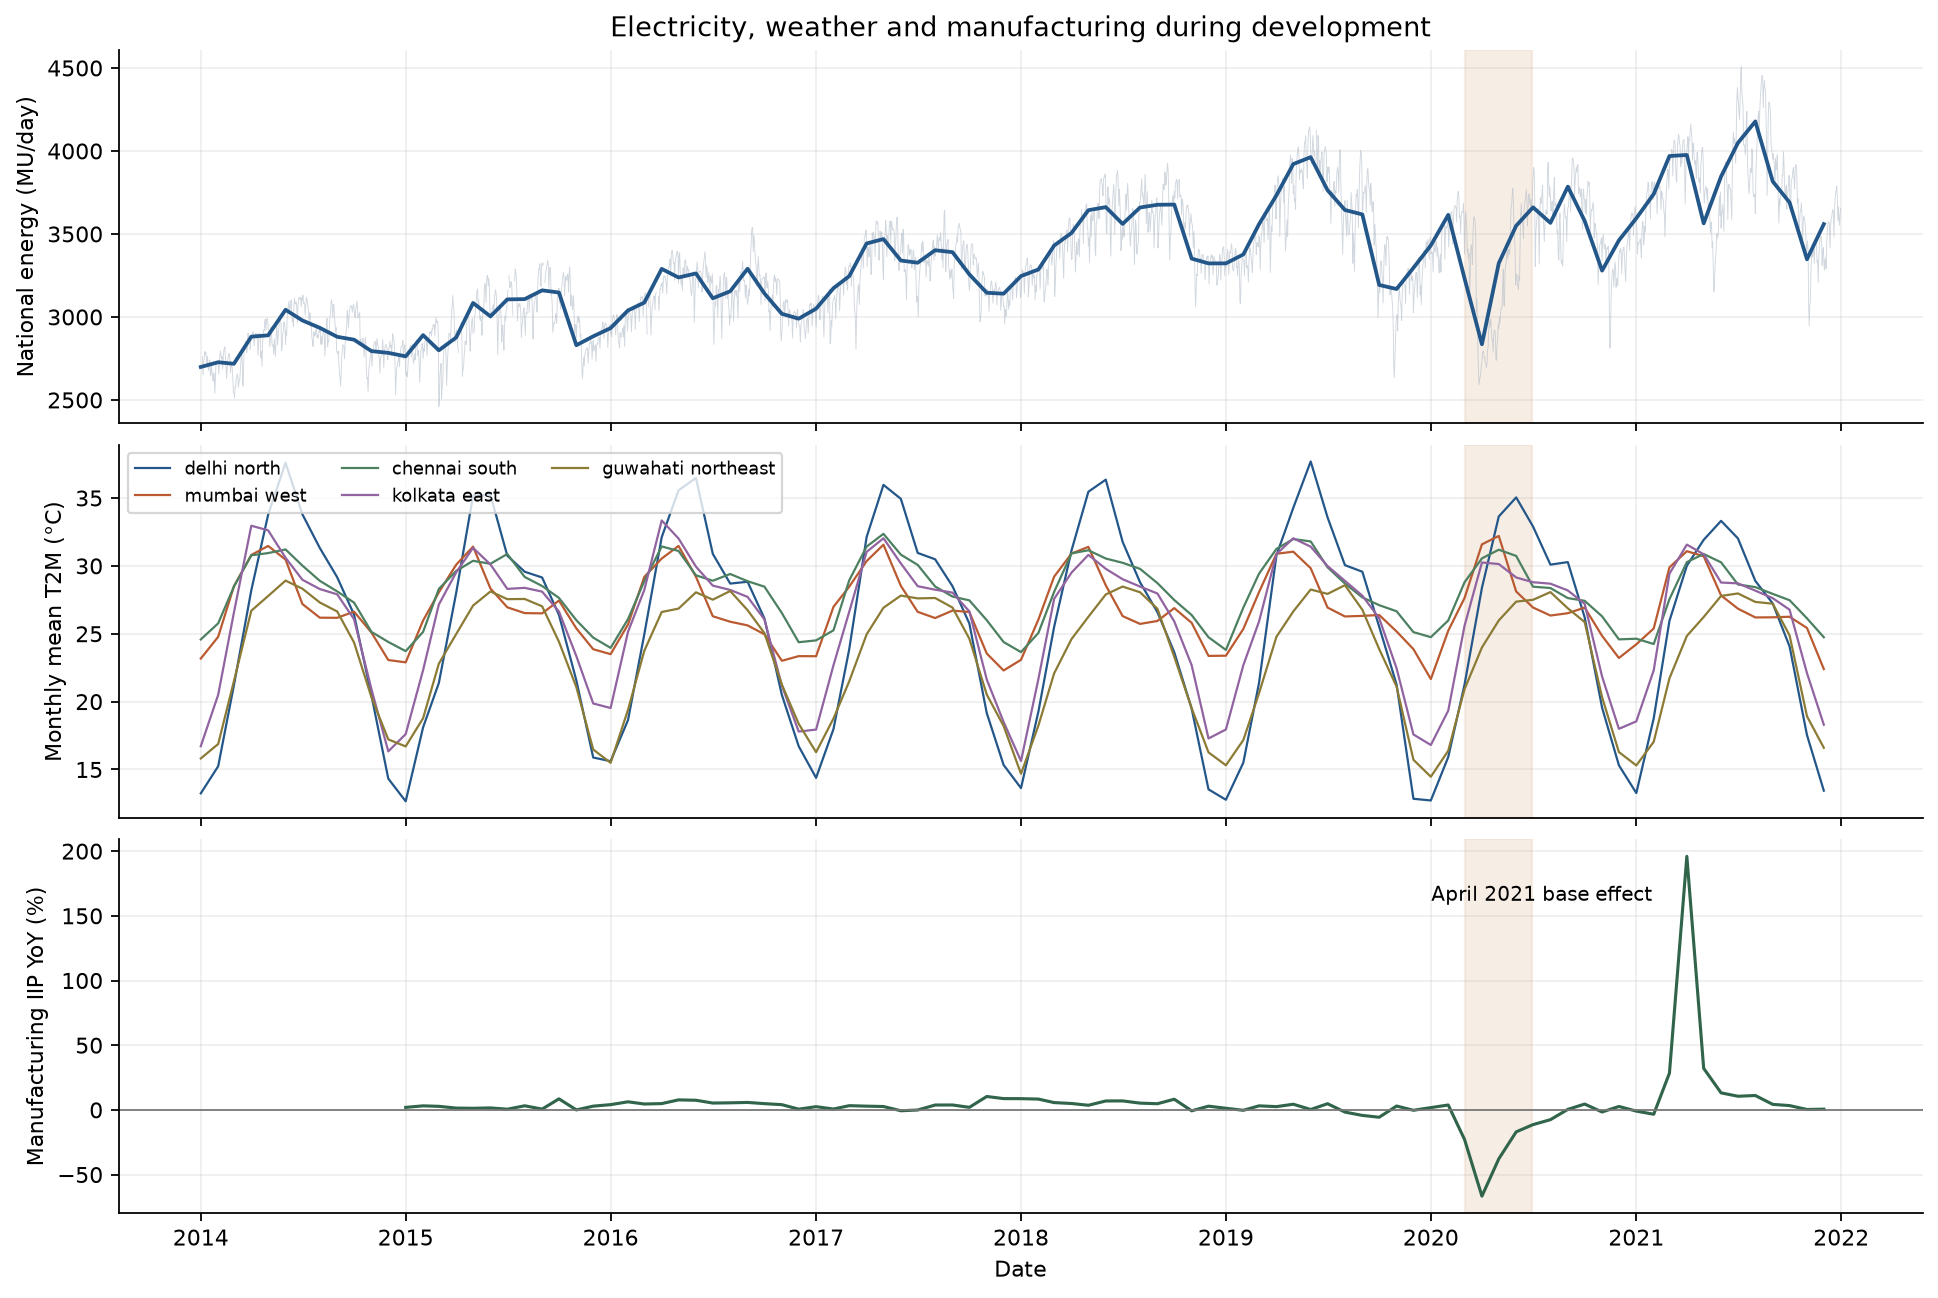

Saved output/data_checks/development_history.png


In [2]:
development = daily.loc[:"2021-12-31"].copy()
energy = development["energy_MU"].where(development["energy_usable"])
monthly_energy = energy.resample("MS").mean()
monthly_weather = development.filter(regex="_T2M_C$").resample("MS").mean()
development_iip = iip.loc["2015-01":"2021-12"]

figure, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
axes[0].plot(energy.index, energy, color="#AAB6C3", lw=.4, alpha=.55)
axes[0].plot(monthly_energy.index, monthly_energy, color="#235789", lw=1.7)
axes[0].set(ylabel="National energy (MU/day)", title="Electricity, weather and manufacturing during development")
colors = ["#235789", "#BA5A31", "#4C8061", "#9163A0", "#8C7B35"]
for column, color in zip(monthly_weather, colors):
    label = column.removesuffix("_T2M_C").replace("_", " ")
    axes[1].plot(monthly_weather.index, monthly_weather[column], color=color, label=label, lw=1)
axes[1].set(ylabel="Monthly mean T2M (°C)")
axes[1].legend(ncol=3, fontsize=8, loc="upper left")
axes[2].plot(development_iip.index.to_timestamp(), development_iip.yoy_pct, color="#31654B", lw=1.4)
axes[2].axhline(0, color="#777777", lw=.8)
axes[2].set(ylabel="Manufacturing IIP YoY (%)", xlabel="Date")
axes[2].annotate("April 2021 base effect", xy=(pd.Timestamp("2021-04-01"), development_iip.loc["2021-04", "yoy_pct"]), xytext=(-115, -20), textcoords="offset points", fontsize=9)
for axis in axes:
    axis.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-30"), color="#EDD8C7", alpha=.45)
save_figure(figure, "development_history.png")

## Weekday and seasonal variation

Each usable daily energy value is divided by that calendar year’s mean and multiplied by 100. This normalization is descriptive and uses only the development sample. It is not a preprocessing step for the forecasting models. Thin lines show individual years; the strong line shows the average annual profile. The model adjustment is estimated separately within each expanding training window.

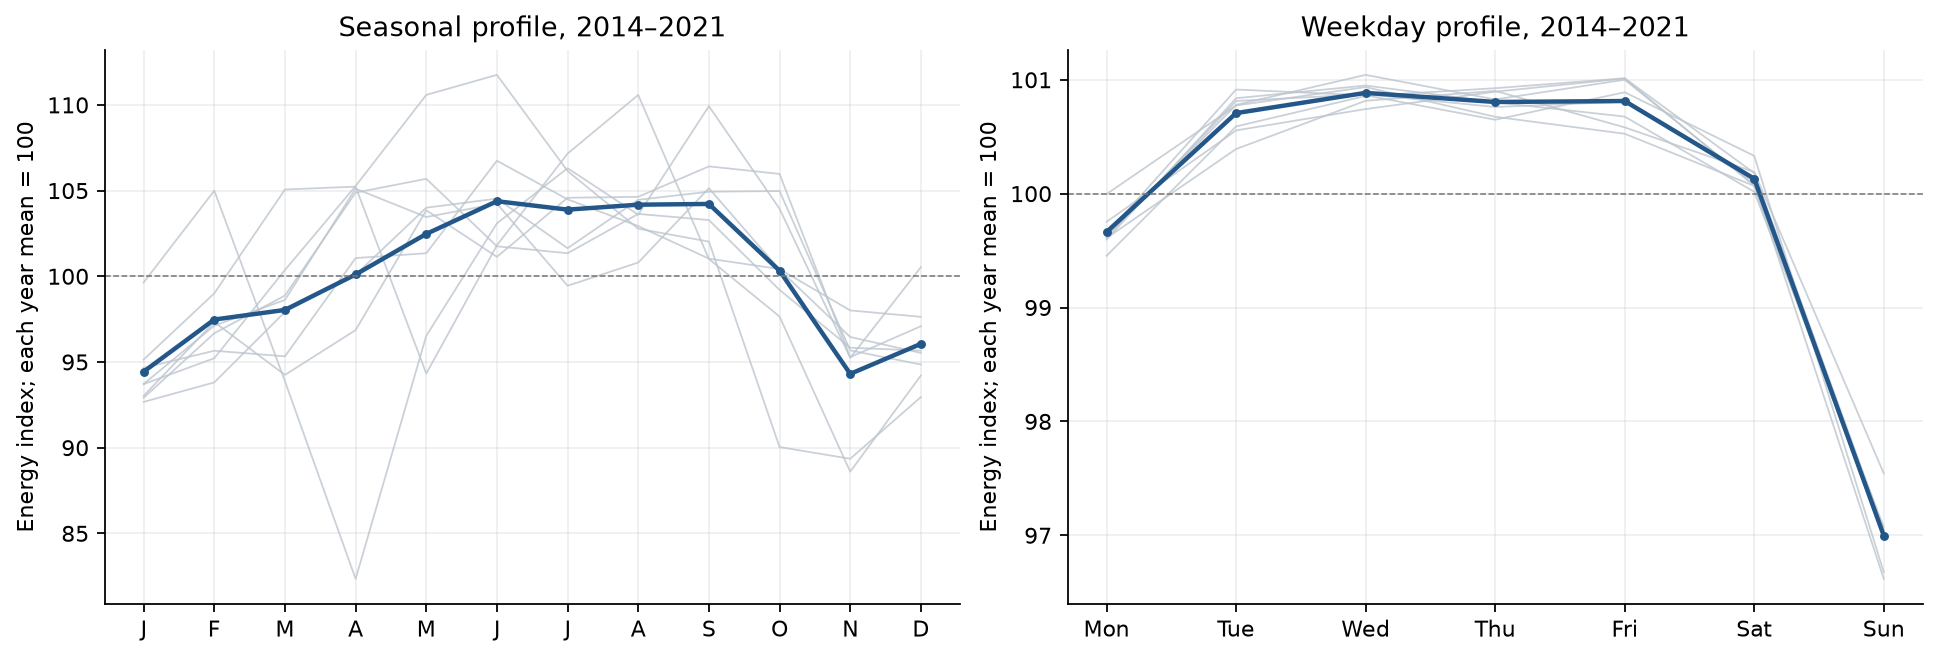

Saved output/data_checks/development_calendar_profiles.png


In [3]:
calendar_data = pd.DataFrame({"energy": energy}).dropna()
calendar_data["year"] = calendar_data.index.year
calendar_data["month"] = calendar_data.index.month
calendar_data["weekday"] = calendar_data.index.dayofweek
calendar_data["within_year_index"] = 100 * calendar_data.energy / calendar_data.groupby("year").energy.transform("mean")
monthly_profiles = calendar_data.groupby(["year", "month"]).within_year_index.mean().unstack("year")
weekday_profiles = calendar_data.groupby(["year", "weekday"]).within_year_index.mean().unstack("year")
figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for axis, profiles, labels in [(axes[0], monthly_profiles, list("JFMAMJJASOND")), (axes[1], weekday_profiles, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])]:
    axis.plot(profiles.index, profiles, color="#BCC5CE", lw=.8, alpha=.8)
    axis.plot(profiles.index, profiles.mean(axis=1), color="#235789", lw=2, marker="o", ms=3)
    axis.axhline(100, color="#777777", lw=.7, linestyle="--")
    axis.set_xticks(profiles.index, labels)
    axis.set_ylabel("Energy index; each year mean = 100")
axes[0].set_title("Seasonal profile, 2014–2021")
axes[1].set_title("Weekday profile, 2014–2021")
save_figure(figure, "development_calendar_profiles.png")

## Observations for the data section

These calculations describe development data. The festival plot below uses source-checked calendar dates; it does not identify a causal holiday effect or industrial demand.

In [4]:
weekday_means = weekday_profiles.mean(axis=1)
seasonal_means = monthly_profiles.mean(axis=1)
weekday_mean = float(weekday_means.loc[0:4].mean())
sunday_mean = float(weekday_means.loc[6])
april_energy_change = 100 * (monthly_energy.loc["2020-04-01"] / monthly_energy.loc["2019-04-01"] - 1)
april_iip_change = float(iip.loc["2020-04", "yoy_pct"])
month_names = {number: pd.Timestamp(2020, number, 1).strftime("%B") for number in range(1, 13)}
observations = [
    f"1. The mean Sunday energy index is {sunday_mean:.2f}, versus {weekday_mean:.2f} across Monday–Friday. The difference motivates weekday controls; it does not identify its cause.",
    f"2. The average within-year seasonal profile ranges from {seasonal_means.min():.2f} in {month_names[int(seasonal_means.idxmin())]} to {seasonal_means.max():.2f} in {month_names[int(seasonal_means.idxmax())]}. Weather and calendar variation should be addressed before interpreting predictive associations.",
    f"3. Mean national energy changes by {april_energy_change:.2f}% from April 2019 to April 2020, while manufacturing IIP growth is {april_iip_change:.2f}%. The joint disruption and the later base effect require prespecified pandemic sensitivity checks."
]
print("\n\n".join(observations))
(FIGURES / "data_observations.json").write_text(json.dumps({"development_end": "2021-12-31", "observations": observations, "festival_diagnostics": "Source-checked Diwali window plotted separately"}, indent=2) + "\n")

1. The mean Sunday energy index is 97.00, versus 100.57 across Monday–Friday. The difference motivates weekday controls; it does not identify its cause.

2. The average within-year seasonal profile ranges from 94.31 in November to 104.38 in June. Weather and calendar variation should be addressed before interpreting predictive associations.

3. Mean national energy changes by -24.05% from April 2019 to April 2020, while manufacturing IIP growth is -66.64%. The joint disruption and the later base effect require prespecified pandemic sensitivity checks.


721

## Festival profile

Daily energy around each checked Diwali date is divided by that year's mean. The primary Diwali date and its adjacent days form one small calendar control. Regional dates and shutdown durations vary; this plot is descriptive.

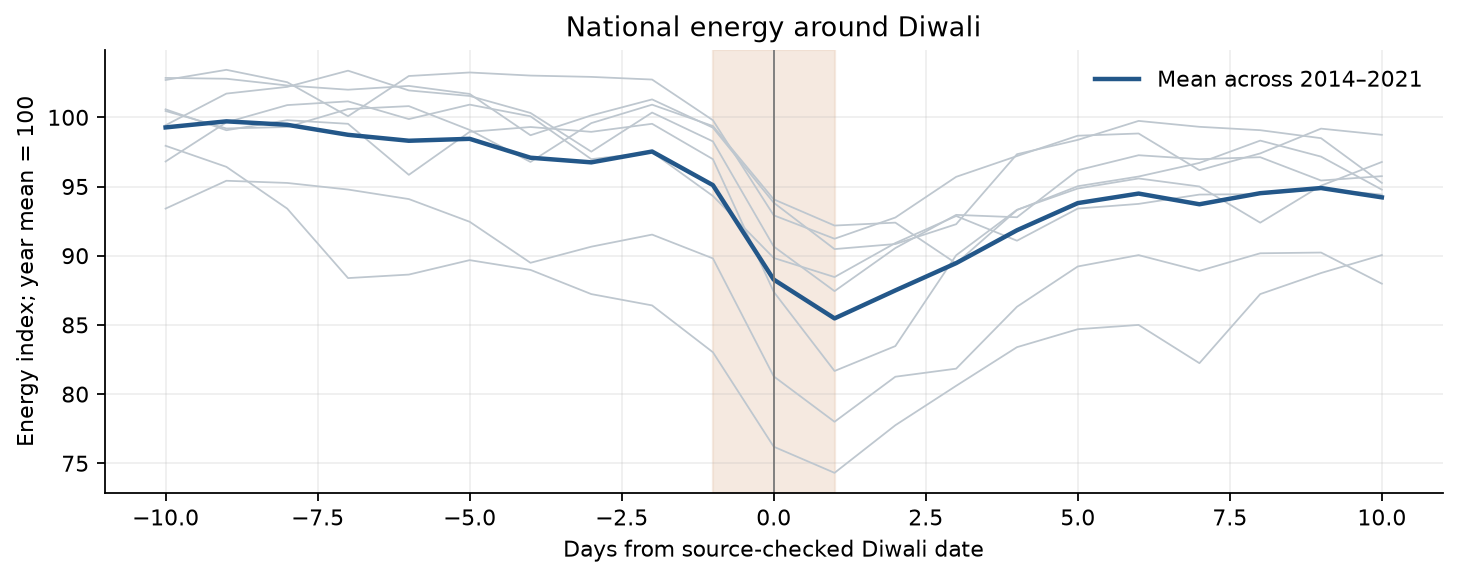

Saved output/data_checks/development_diwali_profile.png


In [5]:
events = pd.read_csv(ROOT / "research/feasibility_2026-10-22/calendar_events.csv", parse_dates=["date"])
festival_rows = []
for day in events.loc[events.event.eq("Diwali") & events.date.dt.year.le(2021), "date"]:
    annual_mean = energy.loc[str(day.year)].mean()
    for relative_day in range(-10, 11):
        value = energy.get(day + pd.Timedelta(days=relative_day), np.nan)
        festival_rows.append({"year": day.year, "relative_day": relative_day, "energy_index": 100 * value / annual_mean})
festival = pd.DataFrame(festival_rows).pivot(index="relative_day", columns="year", values="energy_index")
figure, axis = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
axis.plot(festival.index, festival, color="#BEC7CF", lw=.8)
axis.plot(festival.index, festival.mean(axis=1), color="#235789", lw=2, label="Mean across 2014–2021")
axis.axvspan(-1, 1, color="#EDD8C7", alpha=.55)
axis.axvline(0, color="#777777", lw=.8)
axis.set(xlabel="Days from source-checked Diwali date", ylabel="Energy index; year mean = 100", title="National energy around Diwali")
axis.legend(frameon=False)
save_figure(figure, "development_diwali_profile.png")

## Information rule and methods

There are **two estimator families across four setups: ordinary least squares (OLS) and ridge regression**. OLS chooses coefficients to reduce squared training errors. Ridge adds a penalty that discourages large slope coefficients. Daily weather/calendar adjustment is another OLS regression. Nonlinear temperature features are constructed inputs; the fitted regressions remain linear in their coefficients.

The target is manufacturing IIP year-on-year growth on the 2011–12 base. Each forecast is dated the fifth of the next month. The primary daily lag is five calendar days; a later documented issue date takes precedence. The latest IIP label at evaluation origins is normally target month minus two. Training labels must have been released by the current forecast date, and historical lag features must have been released at their own forecast dates.

The daily adjustment regresses log energy on an intercept, retained linear trend, two annual Fourier harmonics, six weekday indicators, three fixed holidays pooled in one indicator, Diwali ±1 day, and equally weighted pointwise HDD18/CDD24. It subtracts fitted seasonality, calendar and temperature terms while retaining intercept, trend and residual. It is refitted only through the latest released training-label month. No current unlabelled month enters this fit.

Monthly electricity features are cutoff-matched current/prior-year mean energy growth and growth of the last seven-day mean over the previous seven-day mean. Both monthly windows and each weekly window require at least 90% joint energy/weather coverage. Missing values and source exclusions stay missing. All models use identical eligible months. The benchmark includes released IIP lags two and three, annual sine/cosine and the known monthly Diwali-window share. Raw and adjusted OLS add their corresponding electricity features. Adjusted ridge uses training-fold mean/standard-deviation scaling, an unpenalized intercept and penalties 0.1, 1, 10 or 100 selected by validation MAE.

For ridge, the objective is the **sum** of squared training errors plus alpha times the sum of squared standardized slopes, with no 1/n normalization and no intercept penalty. Training standard deviations use the population divisor n. The adjustment notation is: E_d is daily energy, T_d is time in years, Z_d is the seasonal/calendar/temperature input vector, a and b are intercept/trend coefficients, c contains adjustment coefficients, and u_d is residual variation. Hats indicate fitted values; E*_d is adjusted energy.

Initial target training is 2015–2018, expanding validation is 2019–2021, and the final test is 2022–2023. Past validation/test labels enter later training only after release. Validation choices are frozen before final test errors are calculated. Prespecified test sensitivities are daily lags three/seven, 95% coverage, and exclusion of March 2020–June 2021 from daily/monthly training. The primary selected ridge penalty is retained for every sensitivity. The pandemic exclusion removes dated daily adjustment observations and monthly outcome rows, not every pandemic-related lagged predictor or prior-year comparison value. Primary monthly fitting counts span 80–103; exclusion counts span 64–87.

Scoring uses common-month MAE and RMSE in percentage points, with relative improvement over the benchmark. April–June errors are shown separately. Paired mean absolute-error differences use a circular moving-block bootstrap (three consecutive months, 2,000 resamples, seed 241022, percentile 95% interval). Paired comparisons with raw OLS are also shown. Twenty-four test months provide limited information about uncertainty; these intervals are descriptive and sensitive to the block choice. No model is selected using test errors.

In [6]:
RESULTS = ROOT / "results"
config = json.loads((ROOT / "config.json").read_text())
def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
expected_fingerprint = {"config_sha256": digest(ROOT / "config.json"), "backtest_script_sha256": digest(ROOT / "backtest.py"), "data_versions_sha256": digest(DATA / "data_versions.json")}
def verify_run(name):
    metadata = json.loads((RESULTS / name).read_text())
    assert metadata["fingerprint"] == expected_fingerprint, "Saved predictions use different inputs or code"
    for filename, checksum in metadata["outputs"].items():
        assert digest(RESULTS / filename) == checksum, filename
    return metadata
validation_run = verify_run("validation_run.json")
validation = pd.read_csv(RESULTS / "validation_predictions.csv")
validation_metrics = pd.read_csv(RESULTS / "validation_metrics.csv")
print(validation_metrics[["model", "alpha", "months", "MAE_pp", "RMSE_pp"]].to_string(index=False, float_format=lambda value: f"{value:.3f}"))
ledger = pd.read_csv(RESULTS / "validation_information_sets.csv")
print("\nExample information sets:")
print(ledger.iloc[[0, -1]][["month", "forecast_date", "daily_cutoff", "last_training_label", "last_training_release_date", "training_months", "adjustment_last_day"]].to_string(index=False))
print(f"Matched training months range from {ledger.training_months.min()} to {ledger.training_months.max()}; all 36 validation months are retained.")
protocol = {"target": "Manufacturing IIP YoY, 2011–12 base", "evaluation": config["evaluation"], "bootstrap_rule": "Circular moving blocks; identical resampled month indices for each paired model", "scenarios": config["scenarios"], "information_rule": "forecast fifth next month; released labels; refit within training; retain trend", "test_tuning": False}
(RESULTS / "methods_protocol.json").write_text(json.dumps(protocol, indent=2) + "\n")

         model   alpha  months  MAE_pp  RMSE_pp
  adjusted_ols   0.000      36  13.053   29.913
adjusted_ridge   0.100      36  13.039   29.903
adjusted_ridge   1.000      36  12.933   29.826
adjusted_ridge  10.000      36  12.349   29.770
adjusted_ridge 100.000      36  12.042   32.882
 iip_benchmark   0.000      36  15.712   38.488
       raw_ols   0.000      36  14.312   31.609

Example information sets:
  month forecast_date daily_cutoff last_training_label last_training_release_date  training_months adjustment_last_day
2019-01    2019-02-05   2019-01-31             2018-11                 2019-01-11               44          2018-11-30
2021-12    2022-01-05   2021-12-31             2021-10                 2021-12-10               79          2021-10-31
Matched training months range from 44 to 79; all 36 validation months are retained.


1281

## Adjustment diagnostics and validation errors

The saved daily snapshot is transformed using the final validation origin's training fit, ending October 2021. It preserves trend and unexplained variation; the adjusted level has an arbitrary calendar baseline. For visual comparison, each series is indexed to its own 2014 mean. Diagnostics cannot establish that the remaining variation is manufacturing activity.

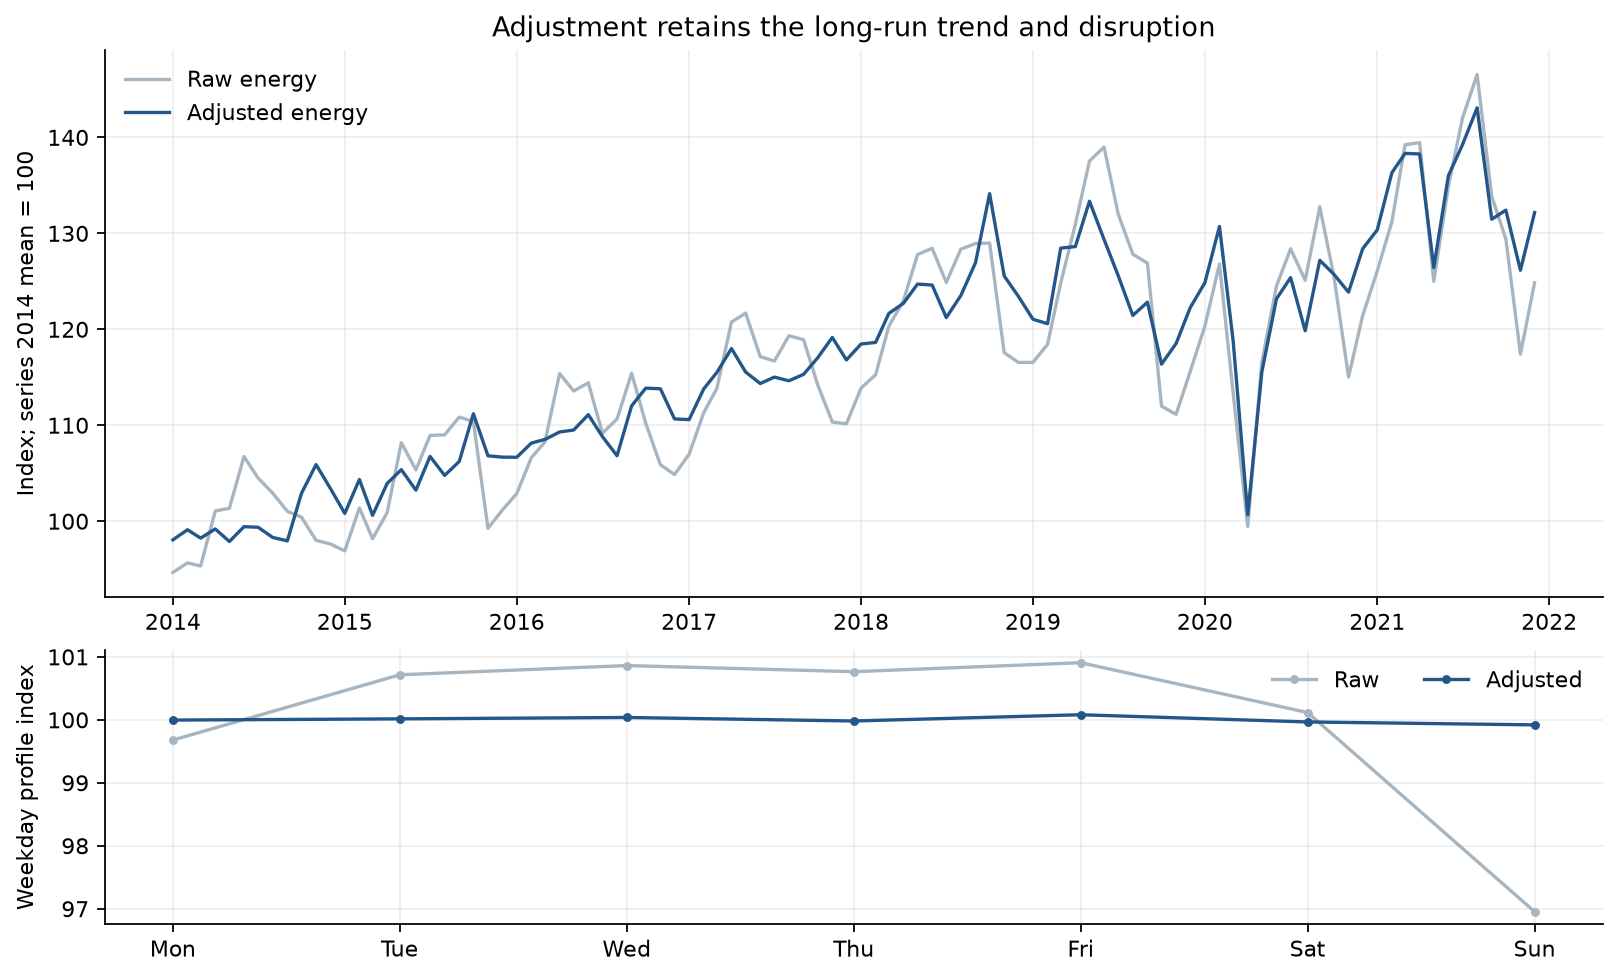

Saved output/data_checks/development_adjustment_diagnostics.png

Validation by year, pp:
                     MAE_pp  RMSE_pp
year model                          
2019 adjusted_ols     2.714    3.383
     adjusted_ridge   2.821    3.664
     iip_benchmark    3.012    3.826
     raw_ols          3.105    3.688
2020 adjusted_ols    11.787   20.698
     adjusted_ridge  12.076   22.781
     iip_benchmark   16.039   26.653
     raw_ols         12.571   21.000
2021 adjusted_ols    24.659   47.377
     adjusted_ridge  21.228   52.070
     iip_benchmark   28.086   60.983
     raw_ols         27.261   50.426


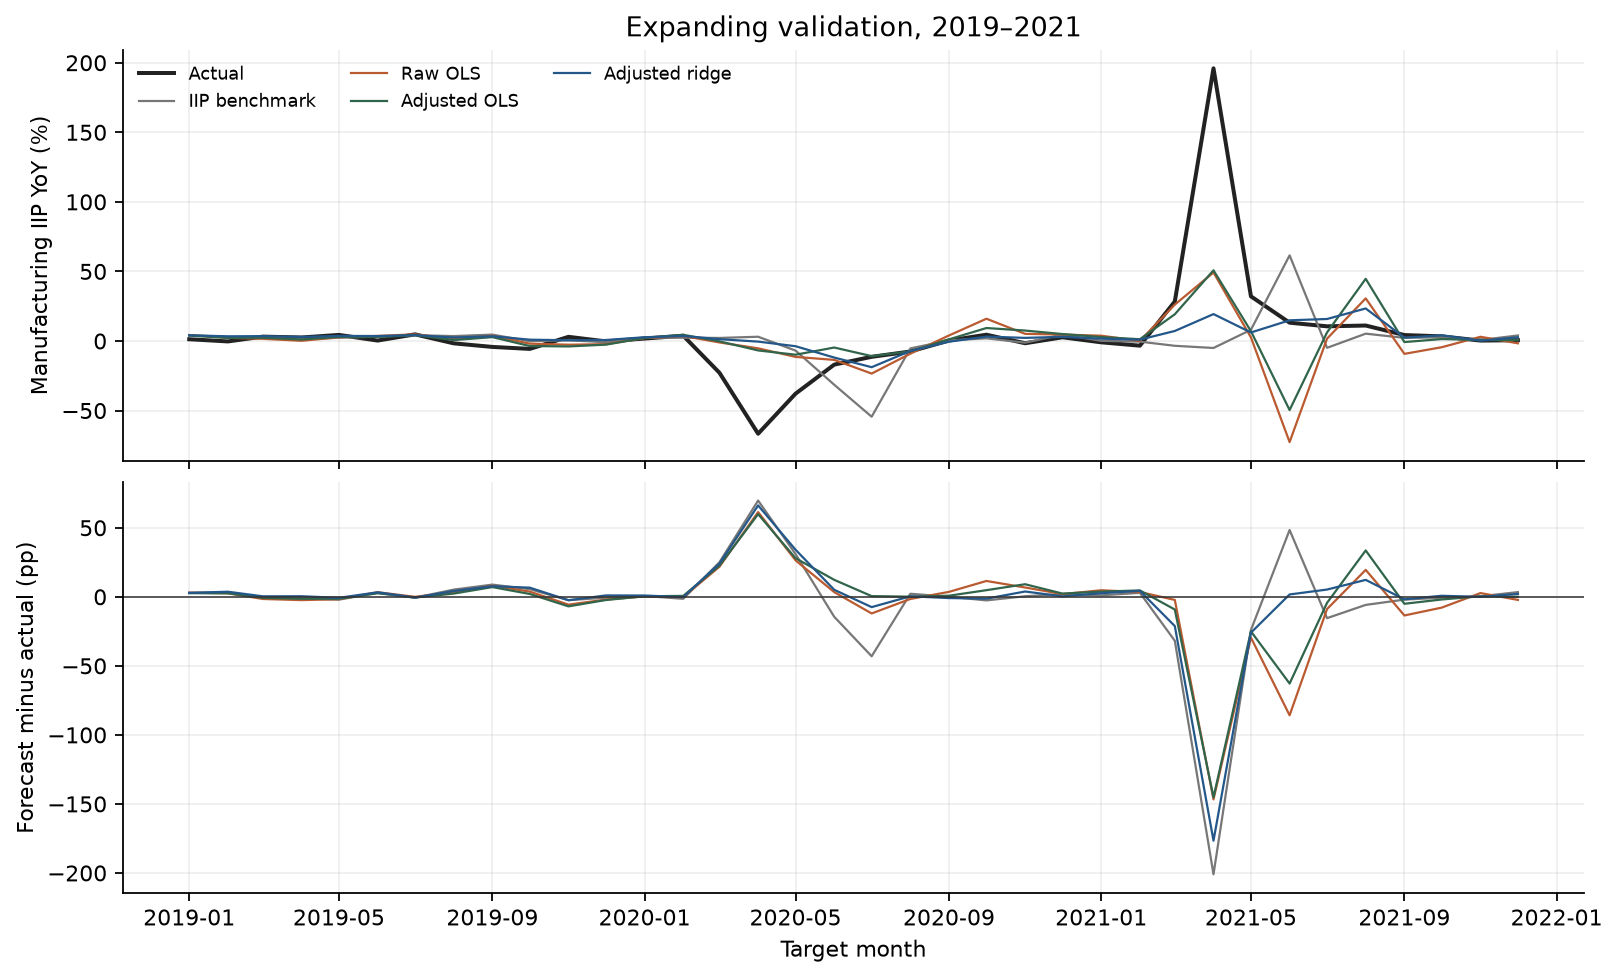

Saved output/data_checks/validation_predictions_and_errors.png
Validation MAE selects ridge alpha=100. Selection does not use final test errors.


In [7]:
adjusted = pd.read_csv(RESULTS / "validation_adjusted_daily_snapshot.csv", parse_dates=["date"]).set_index("date")
indexed = adjusted[["raw_energy", "adjusted_energy"]] / adjusted.loc["2014", ["raw_energy", "adjusted_energy"]].mean() * 100
profiles = indexed.groupby(indexed.index.dayofweek).mean()
figure, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True, gridspec_kw={"height_ratios": [2, 1]})
monthly_indexed = indexed.resample("MS").mean()
axes[0].plot(monthly_indexed.index, monthly_indexed.raw_energy, color="#A7B5C1", label="Raw energy")
axes[0].plot(monthly_indexed.index, monthly_indexed.adjusted_energy, color="#235789", label="Adjusted energy")
axes[0].set(ylabel="Index; series 2014 mean = 100", title="Adjustment retains the long-run trend and disruption")
axes[0].legend(frameon=False)
for column, color, label in [("raw_energy", "#A7B5C1", "Raw"), ("adjusted_energy", "#235789", "Adjusted")]:
    relative = profiles[column] / profiles[column].mean() * 100
    axes[1].plot(range(7), relative, color=color, label=label, marker="o", ms=3)
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set(ylabel="Weekday profile index")
axes[1].legend(frameon=False, ncol=2)
save_figure(figure, "development_adjustment_diagnostics.png")
selected_alpha = float(validation_metrics.loc[validation_metrics.model.eq("adjusted_ridge")].sort_values(["MAE_pp", "alpha"]).iloc[0].alpha)
chosen_validation = validation.loc[~validation.model.eq("adjusted_ridge") | validation.alpha.eq(selected_alpha)].copy()
chosen_validation["error_pp"] = chosen_validation.prediction_pct - chosen_validation.actual_pct
validation_by_year = chosen_validation.assign(year=chosen_validation.month.str[:4]).groupby(["year", "model"]).error_pp.agg(MAE_pp=lambda x: x.abs().mean(), RMSE_pp=lambda x: np.sqrt(np.mean(x**2)))
print("\nValidation by year, pp:")
print(validation_by_year.to_string(float_format=lambda x: f"{x:.3f}"))
figure, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
labels = {"iip_benchmark": "IIP benchmark", "raw_ols": "Raw OLS", "adjusted_ols": "Adjusted OLS", "adjusted_ridge": "Adjusted ridge"}
model_colors = {"iip_benchmark": "#777777", "raw_ols": "#BA5A31", "adjusted_ols": "#31654B", "adjusted_ridge": "#235789"}
actual_validation = chosen_validation.drop_duplicates("month")
axes[0].plot(pd.to_datetime(actual_validation.month), actual_validation.actual_pct, color="#222222", label="Actual", lw=1.8)
for model, group in chosen_validation.groupby("model", sort=False):
    dates = pd.to_datetime(group.month)
    axes[0].plot(dates, group.prediction_pct, color=model_colors[model], label=labels[model], lw=1)
    axes[1].plot(dates, group.error_pp, color=model_colors[model], lw=1)
axes[0].set(ylabel="Manufacturing IIP YoY (%)", title="Expanding validation, 2019–2021")
axes[0].legend(frameon=False, ncol=3, fontsize=8)
axes[1].axhline(0, color="#333333", lw=.7)
axes[1].set(ylabel="Forecast minus actual (pp)", xlabel="Target month")
save_figure(figure, "validation_predictions_and_errors.png")
print(f"Validation MAE selects ridge alpha={selected_alpha:g}. Selection does not use final test errors.")

## Frozen test results and robustness

These cells read final predictions only if the saved experiment freeze and its hashes match. The 2022–2023 errors cannot alter the specification or selected ridge penalty. Relative improvements are positive when a model lowers error.

Primary final test, 2022–2023:
         model  months  MAE_pp  RMSE_pp  MAE_improvement_pct  RMSE_improvement_pct
  adjusted_ols      24  13.113   14.758             -256.784              -191.507
adjusted_ridge      24   4.842    5.413              -31.746                -6.908
 iip_benchmark      24   3.675    5.063                0.000                 0.000
       raw_ols      24  12.674   14.516             -244.824              -186.713

Prespecified sensitivities:
         scenario          model  months  MAE_pp  RMSE_pp
       coverage95   adjusted_ols      24  13.329   15.035
       coverage95 adjusted_ridge      24   4.707    5.316
       coverage95  iip_benchmark      24   3.757    5.105
       coverage95        raw_ols      24  12.846   14.734
             lag3   adjusted_ols      24  13.113   14.758
             lag3 adjusted_ridge      24   4.842    5.413
             lag3  iip_benchmark      24   3.675    5.063
             lag3        raw_ols      24  12.674   14.516
   


Hot-season breakdown (April–June):
 hot_season          model  months  MAE_pp  RMSE_pp
      False   adjusted_ols      18  13.337   14.594
      False adjusted_ridge      18   5.352    5.905
      False  iip_benchmark      18   3.367    4.197
      False        raw_ols      18  11.314   12.499
       True   adjusted_ols       6  12.441   15.242
       True adjusted_ridge       6   3.313    3.548
       True  iip_benchmark       6   4.599    7.049
       True        raw_ols       6  16.753   19.342


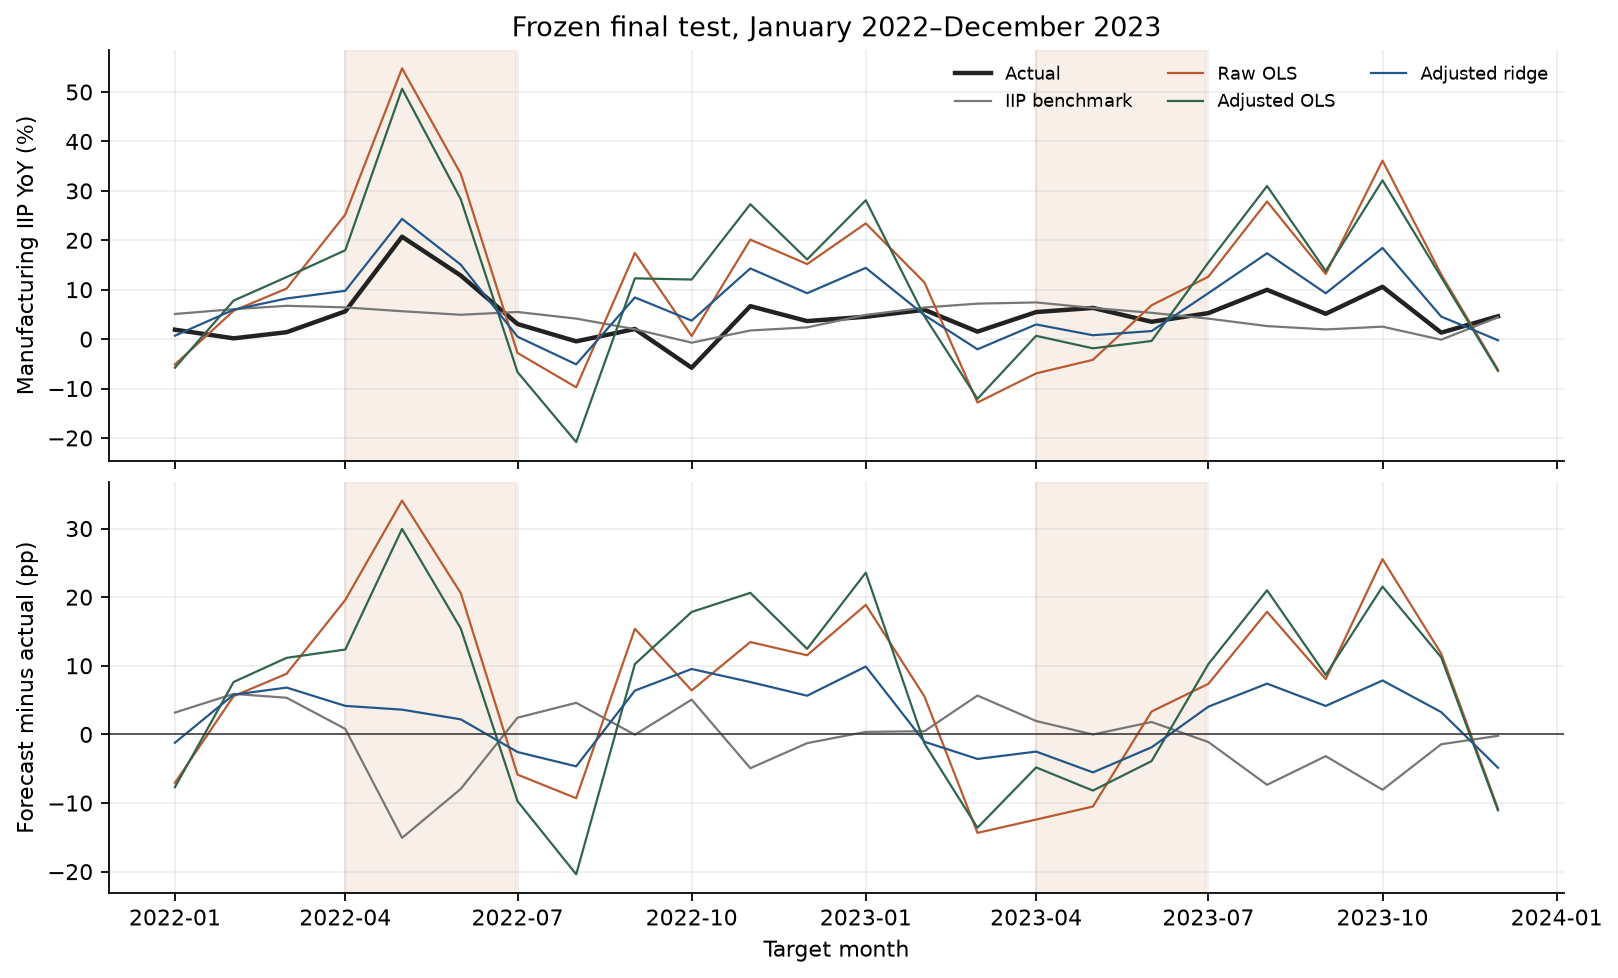

Saved output/data_checks/test_predictions_and_errors.png


In [8]:
test_available = (RESULTS / "test_run.json").exists()
if not test_available:
    print("Final test not yet opened. Complete validation review and save the experiment freeze first.")
else:
    frozen = json.loads((RESULTS / "experiment_freeze.json").read_text())
    assert frozen["fingerprint"] == expected_fingerprint
    assert frozen["test_errors_seen_at_freeze"] is False
    assert frozen["validation_run_sha256"] == digest(RESULTS / "validation_run.json")
    test_run = verify_run("test_run.json")
    assert test_run["experiment_id"] == digest(RESULTS / "experiment_freeze.json")
    predictions = pd.read_csv(RESULTS / "predictions.csv")
    primary = predictions.loc[predictions.scenario.eq("primary")].copy()
    primary["error_pp"] = primary.prediction_pct - primary.actual_pct
    metrics = pd.read_csv(RESULTS / "metrics.csv")
    baseline = metrics.loc[metrics.model.eq("iip_benchmark"), ["scenario", "MAE_pp", "RMSE_pp"]].rename(columns={"MAE_pp": "benchmark_MAE", "RMSE_pp": "benchmark_RMSE"})
    comparison = metrics.merge(baseline, on="scenario", validate="many_to_one")
    comparison["MAE_improvement_pct"] = 100 * (1 - comparison.MAE_pp / comparison.benchmark_MAE)
    comparison["RMSE_improvement_pct"] = 100 * (1 - comparison.RMSE_pp / comparison.benchmark_RMSE)
    comparison.to_csv(RESULTS / "report_accuracy.csv", index=False, float_format="%.12g")
    print("Primary final test, 2022–2023:")
    print(comparison.loc[comparison.scenario.eq("primary"), ["model", "months", "MAE_pp", "RMSE_pp", "MAE_improvement_pct", "RMSE_improvement_pct"]].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print("\nPrespecified sensitivities:")
    print(comparison[["scenario", "model", "months", "MAE_pp", "RMSE_pp"]].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    primary["hot_season"] = pd.to_datetime(primary.month).dt.month.isin(config["evaluation"]["hot_season_months"])
    seasonal = primary.groupby(["hot_season", "model"]).error_pp.agg(months="size", MAE_pp=lambda x: x.abs().mean(), RMSE_pp=lambda x: np.sqrt(np.mean(x**2))).reset_index()
    seasonal.to_csv(RESULTS / "report_hot_season.csv", index=False, float_format="%.12g")
    print("\nHot-season breakdown (April–June):")
    print(seasonal.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    figure, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
    actual = primary.drop_duplicates("month")
    axes[0].plot(pd.to_datetime(actual.month), actual.actual_pct, color="#222222", label="Actual", lw=2)
    for model, group in primary.groupby("model", sort=False):
        axes[0].plot(pd.to_datetime(group.month), group.prediction_pct, color=model_colors[model], label=labels[model], lw=1)
        axes[1].plot(pd.to_datetime(group.month), group.error_pp, color=model_colors[model], lw=1)
    for year in [2022, 2023]:
        for axis in axes: axis.axvspan(pd.Timestamp(year, 4, 1), pd.Timestamp(year, 6, 30), color="#EDD8C7", alpha=.4)
    axes[0].set(ylabel="Manufacturing IIP YoY (%)", title="Frozen final test, January 2022–December 2023")
    axes[0].legend(frameon=False, ncol=3, fontsize=8)
    axes[1].axhline(0, color="#333333", lw=.7)
    axes[1].set(ylabel="Forecast minus actual (pp)", xlabel="Target month")
    save_figure(figure, "test_predictions_and_errors.png")

## Paired uncertainty and interpretation

Negative paired differences favour the model named first. The same resampled monthly blocks are applied to both models. The short test sample, revised values, national supply mix, supply constraints and temperature-point approximation limit generalization. A predictive association does not estimate manufacturing's electricity elasticity.

In [9]:
if test_available:
    absolute = primary.assign(absolute_error=primary.error_pp.abs()).pivot(index="month", columns="model", values="absolute_error").sort_index()
    n = len(absolute)
    block = config["evaluation"]["block_months"]
    repetitions = config["evaluation"]["bootstrap_repetitions"]
    rng = np.random.default_rng(config["evaluation"]["bootstrap_seed"])
    starts = rng.integers(0, n, size=(repetitions, int(np.ceil(n / block))))
    sampled_indices = ((starts[:, :, None] + np.arange(block)) % n).reshape(repetitions, -1)[:, :n]
    paired_rows = []
    for reference in ["iip_benchmark", "raw_ols"]:
        for model in ["raw_ols", "adjusted_ols", "adjusted_ridge"]:
            if reference == model: continue
            differences = (absolute[model] - absolute[reference]).to_numpy()
            draws = differences[sampled_indices].mean(axis=1)
            lower, upper = np.quantile(draws, [.025, .975])
            paired_rows.append({"model": model, "reference": reference, "months": n, "mean_MAE_difference_pp": float(differences.mean()), "lower_95_pp": float(lower), "upper_95_pp": float(upper), "block_months": block, "bootstrap_repetitions": repetitions})
    paired = pd.DataFrame(paired_rows)
    paired.to_csv(RESULTS / "report_paired_uncertainty.csv", index=False, float_format="%.12g")
    print(paired.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    primary_summary = comparison.loc[comparison.scenario.eq("primary")].set_index("model")
    interpretation = {"experiment_id": test_run["experiment_id"], "common_test_months": n, "selected_ridge_alpha": frozen["selected_ridge_alpha"], "primary_accuracy": primary_summary.reset_index().to_dict("records"), "paired_uncertainty": paired.to_dict("records"), "limitations": config["limitations"] + [config["weather_time_rule"], "Only 24 final-test months; block intervals are exploratory.", "Grid supply includes residential, agricultural and service loads and is affected by supply constraints.", "The festival calendar is a small proxy and omits many regional holidays."]}
    (RESULTS / "report_summary.json").write_text(json.dumps(interpretation, indent=2) + "\n")
    print("\nNo test-based retuning was performed. Read sensitivity changes alongside the primary result and its short-sample uncertainty.")

         model     reference  months  mean_MAE_difference_pp  lower_95_pp  upper_95_pp  block_months  bootstrap_repetitions
       raw_ols iip_benchmark      24                   8.998        6.938       11.360             3                   2000
  adjusted_ols iip_benchmark      24                   9.438        7.225       11.511             3                   2000
adjusted_ridge iip_benchmark      24                   1.167       -0.877        2.907             3                   2000
  adjusted_ols       raw_ols      24                   0.440       -1.740        2.551             3                   2000
adjusted_ridge       raw_ols      24                  -7.831      -11.550       -5.098             3                   2000

No test-based retuning was performed. Read sensitivity changes alongside the primary result and its short-sample uncertainty.


## Historical report demonstration

The audited 31 December 2023 report supplies 4,102 MU after rounding. The official XLS retains 4,101.63 MU. At the 5 January 2024 forecast, its arrival completes the last seven-day window. The following record shows the coverage check and the already saved frozen prediction; it fits no model.

In [10]:
demo = json.loads((RESULTS / "historical_demo.json").read_text())
print(json.dumps(demo, indent=2))

{
  "target_month": "2023-12",
  "forecast_date": "2024-01-05",
  "daily_cutoff": "2023-12-31",
  "latest_released_iip_month": "2023-10",
  "latest_iip_release_date": "2023-12-12",
  "source_date": "2023-12-31",
  "printed_reporting_date": "2024-01-01",
  "source_url": "https://webcdn.grid-india.in/files/grdw/uploads/daily-reports/psp-reports/2023-2024/31.12.23_NLDC_PSP.pdf",
  "printed_energy_MU": 4102.0,
  "official_xls_energy_MU": 4101.63,
  "before_report": {
    "monthly_coverage": 0.967741935483871,
    "last_week_coverage": 0.8571428571428571,
    "raw_energy_yoy_pct": 1.5240813014838261,
    "forecast_ready": false
  },
  "after_report": {
    "monthly_coverage": 1.0,
    "last_week_coverage": 1.0,
    "raw_energy_yoy_pct": 1.6334337225133,
    "forecast_ready": true
  },
  "saved_frozen_predictions": [
    {
      "model": "iip_benchmark",
      "prediction_pct": 4.42129316137
    },
    {
      "model": "raw_ols",
      "prediction_pct": -6.19770045952
    },
    {
      "mod

## Reproduction and source evidence

### Reproduce the delivered frozen experiment

Use Python 3.12 and the pinned requirements. From the project root, run the following commands using your project environment:

```sh
python prepare_data.py
python backtest.py --stage test
python -m nbconvert --to notebook --execute report.ipynb --inplace --ExecutePreprocessor.timeout=120
```

Preparation verifies the frozen cache offline. The test command verifies the existing code/config/data and validation hashes before recreating frozen test outputs. This notebook reads the saved predictions and regenerates its tables and figures. Keep the existing `results/experiment_freeze.json`; do not run validation or create a new freeze in the delivered project.

### Independently replay validation in a separate copy

Copy the project to a separate directory. In that copy only, move its existing `results` directory aside to preserve the saved comparison files. Run `python prepare_data.py` and `python backtest.py --stage validation` in the copy. Compare the regenerated validation outputs with the saved originals. This validates the original selection step without overwriting this project's experiment freeze. A new experiment requires a separate prospective validation, review, freeze and test sequence; do not select new settings from these test results.

Primary source evidence and exact versions are listed in `data/processed/data_versions.json`. The 30 visually transcribed original-report checks are in `research/feasibility_2026-10-22/report_sample.csv`; unresolved dates/source conflicts are recorded in the `energy_exclusions` entries of `config.json` and in `data/processed/report_audit.csv`. Calendar URLs and hashes are in `research/feasibility_2026-10-22/calendar_events.csv` and `research/feasibility_2026-10-22/calendar_download_manifest.json`. IIP first-release dates are checked for every validation/test origin; older training dates remain explicitly nominal. Original release-vintage values are not reconstructed. Raw CSV redistribution terms remain unverified.

Sources: [Grid India reports](https://grid-india.in/en/reports/daily-psp-report), [Robbie Andrew (CICERO) electricity data](https://robbieandrew.github.io/india/), [MoSPI historical IIP API](https://api.mospi.gov.in/api/iip/getIIPData?frequency=Monthly&base_year=2011-12&category_code=2&limit=200&page=1), [NASA POWER](https://power.larc.nasa.gov/docs/services/api/temporal/daily/). Additional conceptual sources include [Giannone, Reichlin and Small, ECB Working Paper 633](https://www.ecb.europa.eu/pub/pdf/scpwps/ecbwp633.pdf), [Blonz and Williams](https://doi.org/10.17016/2380-7172.2781), and [Hunt and Bloomfield](https://doi.org/10.1088/2753-3751/adc7bc). Further source attribution and study evidence are listed in `SOURCES.md`.
